# ¿Raciona crédito el techo de usura? Evidencia semanal de Colombia, 2007–2022

**Pregunta.** En Colombia la tasa de un crédito de consumo u ordinario no puede superar 1,5 veces el interés bancario
corriente que certifica la SFC. Si ese techo restringe, los prestamistas que operan pegados a él, al bajar el techo, deben
bajar el precio. La pregunta económica es qué pasa con la cantidad: si el techo solo transfiere renta del prestamista al
deudor, la cantidad no cambia; si raciona, los prestamistas dejan de atender a los deudores marginales y la cantidad cae.

**Contribución del ejercicio.** Usa la variación de alta frecuencia del techo (recortes mensuales o trimestrales, decididos
con una fórmula y no por la entidad) y la heterogeneidad entre celdas entidad-producto-plazo en qué tanto las restringe.

**Datos.** SFC, tasas efectivas anuales y montos desembolsados semanales por entidad, modalidad y plazo (datos.gov.co
`yvb2-ppaa`, 2002–2022), y el interés bancario corriente certificado por modalidad (`pare-7x5i`, desde abril de 2007).

**Relación con la literatura.** Amontonamiento como evidencia de una restricción que muerde (Chetty, Friedman, Olsen y
Pistaferri, 2011, *QJE*); estudio de eventos apilado para choques escalonados (Cengiz, Dube, Lindner y Zipperer, 2019, *QJE*);
efectos de los techos de usura sobre la oferta de crédito (Benmelech y Moskowitz, 2010, *Journal of Finance*; Rigbi, 2013,
*Review of Economics and Statistics*).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd())); sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import usura_efectos as U
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
p = U.panel(); ev = U.eventos()
print(f"Celda-semanas: {len(p):,}; entidades: {p.codigo_entidad.nunique()}; de {p.semana.min().date()} a {p.semana.max().date()}")
print(p.producto.value_counts().to_string())
print(f"\nCambios del techo de al menos 25 pb: {len(ev)} ({(ev.cambio_pp<0).sum()} recortes, {(ev.cambio_pp>0).sum()} alzas); "
      f"mediana del recorte {ev.loc[ev.cambio_pp<0,'cambio_pp'].median():.2f} pp")

Celda-semanas: 387,571; entidades: 75; de 2007-04-06 a 2022-06-24
producto
Consumo                104124
Comercial ordinario    102252
Tarjeta personas        94388
Tarjeta empresarial     58122
Libranza                14600
Sobregiro               14085

Cambios del techo de al menos 25 pb: 59 (31 recortes, 28 alzas); mediana del recorte -0.50 pp


## 1. ¿Muerde el techo? Amontonamiento debajo de 1,0

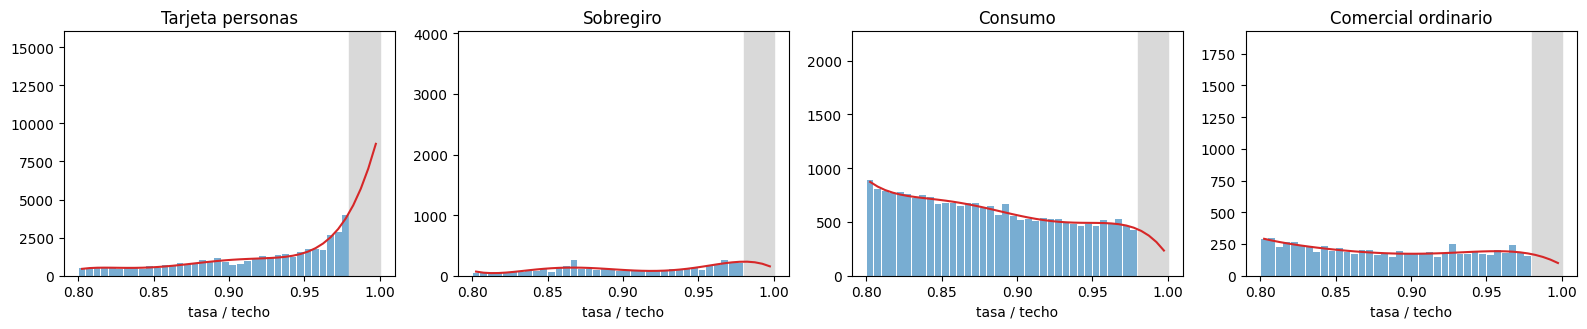

,observaciones,masa_observada_sobre_contrafactual,ic95_bajo,ic95_alto,b
producto,,,,,
Tarjeta personas,78934,1.5076,1.4163,1.5997,2.0302
Sobregiro,9903,7.2854,5.3519,10.1220,25.1416
Consumo,25881,2.8751,2.0752,4.7608,7.5004
Comercial ordinario,9827,4.8248,2.9895,9.2395,15.2993


In [2]:
prods_b = ["Tarjeta personas", "Sobregiro", "Consumo", "Comercial ordinario"]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4))
filas = []
for ax, pr in zip(axs, prods_b):
    a = U.amontonamiento(p, pr)
    lo, hi = U.amontonamiento_bootstrap(p, pr, n=200)
    filas.append({"producto": pr, "observaciones": a["observaciones"], "masa_observada_sobre_contrafactual": a["razon_masa"],
                  "ic95_bajo": lo, "ic95_alto": hi, "b": a["b"]})
    ax.bar(a["centro"], a["cuenta"], width=0.0045, color="tab:blue", alpha=.6)
    ax.plot(a["centro"], a["contrafactual"], color="tab:red")
    ax.axvspan(*a["ventana"], color="0.85"); ax.set_title(pr); ax.set_xlabel("tasa / techo")
plt.tight_layout(); plt.savefig(FIG / "amontonamiento.png", dpi=130); plt.show()
B = pd.DataFrame(filas).set_index("producto"); B

**Lectura.** En los cuatro productos hay mucha más masa en 0,98–1,00 de la que predice un polinomio ajustado fuera de esa
ventana; el intervalo bootstrap, remuestreando semanas completas, está lejos de 1. El techo es una restricción activa para
una parte grande del mercado. Libranza no aparece: su tasa casi nunca se acerca al techo (proyecto 03).

## 2. Estudio de eventos: primera iteración y por qué se descarta

La definición intuitiva de tratamiento es "la celda cobraba en las cuatro semanas previas más que el techo nuevo".

In [3]:
prods = ["Tarjeta personas", "Tarjeta empresarial", "Sobregiro", "Consumo", "Comercial ordinario"]
s0 = U.apilar(p, ev, prods, regla="previa")
es0 = U.estudio_eventos(s0, "tasa_ea")
pt0 = U.prueba_tendencias(es0)
print(f"Tendencias previas en la tasa, regla 'previa': chi2 = {pt0['chi2']:.1f}, gl = {pt0['gl']}, p = {pt0['p']:.1e}")
es0.set_index("rel").coef.round(3).to_frame().T

Tendencias previas en la tasa, regla 'previa': chi2 = 84.6, gl = 7, p = 1.6e-15


rel,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
coef,-0.3550,-0.3140,-0.3010,-0.2210,-0.1260,-0.0450,0.0080,0.0000,-0.4640,-0.6540,-0.6370,-0.5920,-0.6930,-0.7290,-0.7040,-0.7260,-0.7270


Las celdas así seleccionadas venían **subiendo** su tasa justo antes del evento: la regla elige celdas con un alza transitoria
y lo que sigue mezcla el efecto del techo con la reversión a la media (el análogo de la caída de Ashenfelter en evaluación
de programas). El diseño se rechaza.

**Diseño corregido.** El tratamiento se define en una ventana anterior y separada de la de estimación (semanas −12 a −9):
la celda está tratada si en esa ventana su tasa estuvo en promedio al 99% o más del techo vigente, es decir, si opera
pegada al techo de forma habitual. La estimación usa las semanas −8 a +8.

## 3. Resultado principal: recortes del techo

Panel apilado: 242,305 filas; 31 recortes; celdas-evento tratadas 2,529, control 12,811


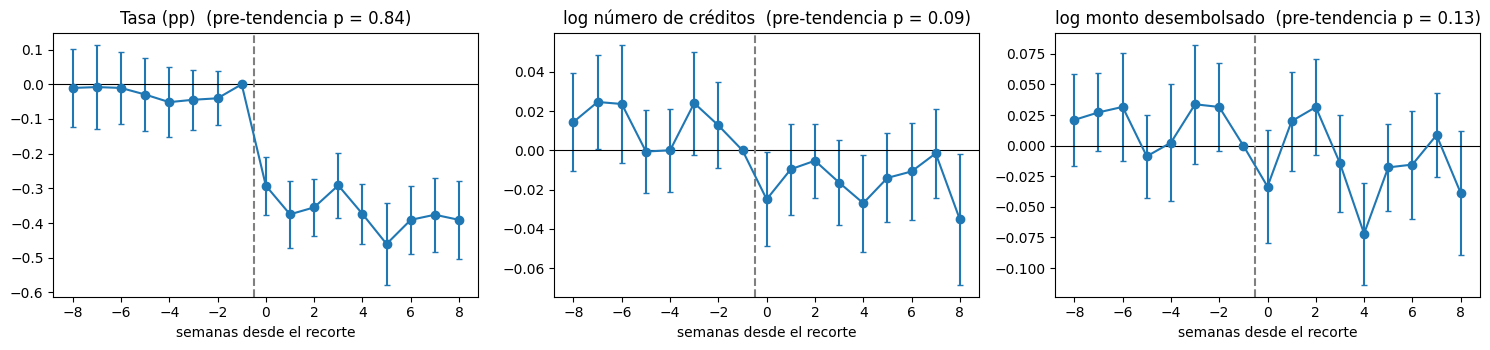

In [4]:
s = U.apilar(p, ev, prods)
print(f"Panel apilado: {len(s):,} filas; {s.evento.nunique()} recortes; celdas-evento tratadas {s.loc[s.tratada==1,'celda_evento'].nunique():,}, "
      f"control {s.loc[s.tratada==0,'celda_evento'].nunique():,}")
ES = {y: U.estudio_eventos(s, y) for y in ["tasa_ea", "log_n", "log_monto"]}
PT = {y: U.prueba_tendencias(e) for y, e in ES.items()}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
titulos = {"tasa_ea": "Tasa (pp)", "log_n": "log número de créditos", "log_monto": "log monto desembolsado"}
for ax, (y, e) in zip(axs, ES.items()):
    ax.errorbar(e.rel, e.coef, yerr=1.96 * e.se, fmt="o-", capsize=2); ax.axhline(0, color="k", lw=.8); ax.axvline(-0.5, color="0.5", ls="--")
    ax.set_title(f"{titulos[y]}  (pre-tendencia p = {PT[y]['p']:.2f})"); ax.set_xlabel("semanas desde el recorte")
plt.tight_layout(); plt.savefig(FIG / "estudio_eventos_recortes.png", dpi=130); plt.show()

In [5]:
R = pd.DataFrame([{**U.did(s, y), "cluster": "evento"} for y in ["tasa_ea", "log_n", "log_monto", "log_ticket"]] +
                 [{**U.did(s, y, cluster="entidad"), "cluster": "entidad"} for y in ["tasa_ea", "log_n", "log_monto", "log_ticket"]])
R[["y", "cluster", "coef", "se", "t", "p", "clusters", "celdas_tratadas", "celdas_control"]]

,y,cluster,coef,se,t,p,clusters,celdas_tratadas,celdas_control
0,tasa_ea,evento,-0.3427,0.0484,-7.0781,0.0000,31,2529,12811
1,log_n,evento,-0.0284,0.0095,-2.9981,0.0027,31,2529,12811
2,log_monto,evento,-0.0320,0.0100,-3.2088,0.0013,31,2529,12811
3,log_ticket,evento,-0.0036,0.0076,-0.4686,0.6394,31,2529,12811
4,tasa_ea,entidad,-0.3427,0.0431,-7.9481,0.0000,71,2529,12811
5,log_n,entidad,-0.0284,0.0127,-2.2342,0.0255,71,2529,12811
6,log_monto,entidad,-0.0320,0.0168,-1.9077,0.0564,71,2529,12811
7,log_ticket,entidad,-0.0036,0.0086,-0.4127,0.6799,71,2529,12811


In [6]:
r_t = R[(R.y == "tasa_ea") & (R.cluster == "evento")].iloc[0]; r_n = R[(R.y == "log_n") & (R.cluster == "evento")].iloc[0]
r_ne = R[(R.y == "log_n") & (R.cluster == "entidad")].iloc[0]
elas = r_n.coef / r_t.coef
print(f"Primera etapa: las celdas pegadas al techo bajan su tasa {abs(r_t.coef):.2f} pp más que el control (t = {r_t.t:.1f}).")
print(f"Cantidad: el número de créditos cae {abs(r_n.coef):.1%} (t = {r_n.t:.1f} agrupando por evento; t = {r_ne.t:.1f} por entidad).")
print(f"Semi-elasticidad implícita: {abs(elas):.1%} menos créditos por cada punto porcentual de recorte forzado de tasa.")
print(f"Pre-tendencias: tasa p = {PT['tasa_ea']['p']:.2f}; número de créditos p = {PT['log_n']['p']:.2f}; monto p = {PT['log_monto']['p']:.2f}.")

Primera etapa: las celdas pegadas al techo bajan su tasa 0.34 pp más que el control (t = -7.1).
Cantidad: el número de créditos cae 2.8% (t = -3.0 agrupando por evento; t = -2.2 por entidad).
Semi-elasticidad implícita: 8.3% menos créditos por cada punto porcentual de recorte forzado de tasa.
Pre-tendencias: tasa p = 0.84; número de créditos p = 0.09; monto p = 0.13.


**Lectura.** Las celdas que operan en el techo bajan precio en la semana del recorte, sin movimiento previo, y atienden menos
créditos en las semanas siguientes. El ticket promedio no cambia, así que el ajuste es en el margen extensivo: se aprueban
menos créditos, no créditos más chicos. Es la firma del racionamiento. El efecto es pequeño por recorte (son recortes
de medio punto), y la inferencia con 31 eventos agrupados es frágil: la prueba de tendencias previas en cantidad tiene
p cercano a 0,1, que no rechaza pero tampoco tranquiliza del todo.

## 4. Falsación y robustez

In [7]:
sb = U.apilar(p, ev, prods, regla="banda")
F = pd.DataFrame([U.did(sb, y) for y in ["tasa_ea", "log_n"]])
print("Celdas cerca del techo pero sin tocarlo (razón habitual 0,90-0,95) frente al resto no pegado al techo:")
F[["y", "coef", "t", "p", "celdas_tratadas"]]

Celdas cerca del techo pero sin tocarlo (razón habitual 0,90-0,95) frente al resto no pegado al techo:


,y,coef,t,p,celdas_tratadas
0,tasa_ea,-0.1676,-2.9478,0.0032,1155
1,log_n,0.0104,1.3454,0.1785,1155


In [8]:
het = []
for pr in prods:
    ss = s[s.producto == pr]
    if ss.tratada.sum() == 0: continue
    a, b = U.did(ss, "tasa_ea"), U.did(ss, "log_n")
    het.append({"producto": pr, "celdas_tratadas": a["celdas_tratadas"], "tasa_pp": a["coef"], "t_tasa": a["t"], "log_n": b["coef"], "t_n": b["t"]})
H = pd.DataFrame(het).set_index("producto"); H

,celdas_tratadas,tasa_pp,t_tasa,log_n,t_n
producto,,,,,
Tarjeta personas,1105,-0.2907,-4.6293,-0.0332,-2.7696
Tarjeta empresarial,967,-0.3593,-5.6867,-0.0205,-1.5342
Sobregiro,251,-0.3583,-6.3458,-0.0432,-1.7621
Consumo,95,-0.5219,-3.1357,-0.0370,-0.5144
Comercial ordinario,111,-0.4581,-3.7129,-0.0088,-0.3224


In [9]:
rob = []
for um in (0.98, 0.99, 0.995):
    ss = U.apilar(p, ev, prods, umbral=um)
    a, b = U.did(ss, "tasa_ea"), U.did(ss, "log_n")
    rob.append({"umbral": um, "celdas_tratadas": a["celdas_tratadas"], "tasa_pp": a["coef"], "log_n": b["coef"], "t_n": b["t"], "semi_elasticidad": b["coef"] / a["coef"]})
ROB = pd.DataFrame(rob).set_index("umbral"); ROB

,celdas_tratadas,tasa_pp,log_n,t_n,semi_elasticidad
umbral,,,,,
0.9800,3382,-0.4009,-0.0334,-3.7429,0.0833
0.9900,2529,-0.3427,-0.0284,-2.9981,0.0829
0.9950,1746,-0.3107,-0.0201,-1.8891,0.0645


La falsación se comporta como debe: en celdas cercanas al techo pero no pegadas a él, la primera etapa es menor y la cantidad
no cae. La semi-elasticidad es estable al mover el umbral que define "pegada al techo". Por producto, el efecto en cantidad
se concentra en tarjeta de personas, que es donde está la mayor parte de las celdas tratadas.

## 5. Alzas del techo: la asimetría

In [10]:
sa = U.apilar(p, ev, prods, direccion="alza")
A = pd.DataFrame([U.did(sa, y) for y in ["tasa_ea", "log_n", "log_monto"]])
ESa = U.estudio_eventos(sa, "tasa_ea"); pta = U.prueba_tendencias(ESa)
print(f"Alzas: pre-tendencia en la tasa p = {pta['p']:.1e}")
A[["y", "coef", "t", "p", "celdas_tratadas"]]

Alzas: pre-tendencia en la tasa p = 1.7e-06


,y,coef,t,p,celdas_tratadas
0,tasa_ea,0.1172,2.3932,0.0167,1920
1,log_n,0.0004,0.0211,0.9832,1920
2,log_monto,0.0190,1.7823,0.0747,1920


Con alzas del techo las celdas pegadas al techo suben su tasa, pero la cantidad no se expande. La lectura está limitada: el
diseño con alzas no pasa la prueba de tendencias previas en la tasa (las alzas del techo suelen venir en rachas, y las celdas
ya venían subiendo). No se usa como evidencia causal; se reporta como asimetría a investigar: si se confirma, sugiere que
los prestamistas ajustan rápido la originación hacia abajo y lento hacia arriba.

## 6. Conclusión, límites y siguiente paso

In [11]:
print(f'''1. El techo muerde: masa en 0,98-1,00 del techo entre {B.masa_observada_sobre_contrafactual.min():.1f} y {B.masa_observada_sobre_contrafactual.max():.1f} veces la contrafactual.
2. Un recorte obliga a las celdas pegadas al techo a bajar {abs(r_t.coef):.2f} pp su tasa y reduce {abs(r_n.coef):.1%} el número de créditos
   (semi-elasticidad {abs(elas):.1%} por pp), sin cambio en el ticket: racionamiento en el margen extensivo.
3. La falsación con celdas cercanas pero no pegadas al techo no muestra efecto en cantidad.''')

1. El techo muerde: masa en 0,98-1,00 del techo entre 1.5 y 7.3 veces la contrafactual.
2. Un recorte obliga a las celdas pegadas al techo a bajar 0.34 pp su tasa y reduce 2.8% el número de créditos
   (semi-elasticidad 8.3% por pp), sin cambio en el ticket: racionamiento en el margen extensivo.
3. La falsación con celdas cercanas pero no pegadas al techo no muestra efecto en cantidad.


**Límites.** (i) La unidad es una celda entidad-producto-plazo, no un crédito: el racionamiento se infiere de la cantidad, no
se observa a quién se rechaza. (ii) 31 recortes: los errores agrupados por evento descansan en pocos grupos; un bootstrap
salvaje por evento es el siguiente paso. (iii) El número de "créditos" en tarjeta cuenta utilizaciones, no tarjetas nuevas.
(iv) El control (celdas lejos del techo) atiende a deudores distintos; los efectos fijos de producto × evento × semana
absorben choques comunes, no choques específicos del segmento riesgoso que coincidan con los recortes. (v) Los datos
semanales terminan en junio de 2022, antes del ciclo de alzas de 2022–2023 y de la reforma de crédito de bajo monto.

**Siguiente paso para una tesis.** Unir con el formato 341 de la SFC o con datos de buró para ver rechazos individuales,
y usar el cambio de 2023 en las modalidades de crédito popular y productivo como segundo experimento.

In [12]:
import json
Path("resultados").mkdir(exist_ok=True)
B.to_csv("resultados/amontonamiento.csv"); R.to_csv("resultados/did_recortes.csv", index=False)
H.to_csv("resultados/heterogeneidad.csv"); ROB.to_csv("resultados/robustez_umbral.csv")
for y, e in ES.items(): e.to_csv(f"resultados/estudio_eventos_{y}.csv", index=False)
Path("resultados/resumen.json").write_text(json.dumps({
    "primera_etapa_pp": float(r_t.coef), "efecto_log_n": float(r_n.coef), "t_evento": float(r_n.t), "t_entidad": float(r_ne.t),
    "semi_elasticidad": float(elas), "pretendencia_p": {k: v["p"] for k, v in PT.items()},
    "recortes": int(s.evento.nunique())}, indent=2))
print("Resultados guardados.")

Resultados guardados.
